# Lab Assignment 5: Word Embeddings — From Co-occurrence to Geometry


**Name:** Muhammad O.A Salam (abdulsalam.m@northeastern.edu)

**Course:** Applied NLP  

**Submission:** Upload `Lab_5.ipynb` to Canvas with all cells run and outputs visible.

---

## Overview

Language models and classifiers need numerical representations of words. The foundational idea behind modern word embeddings is deceptively simple: *words that appear in similar contexts tend to have similar meanings*. This is the distributional hypothesis, and it licenses a surprising leap — that you can learn something real about semantics by counting co-occurrences in raw text.

In this lab you will ground that hypothesis in code. You will build co-occurrence matrices and show quantitatively that distributional neighbours are semantically related. You will train CBOW and Skip-gram Word2Vec models from scratch and compare what each architecture learns. You will evaluate pre-trained GloVe vectors on standard similarity and analogy benchmarks. You will project high-dimensional embeddings into 2D and interpret the geometry. And you will measure the social biases those embeddings encode, using the WEAT framework introduced by Caliskan et al. (2017), assessing what those biases mean for downstream NLP systems.

---

## Learning Objectives

By the end of this lab you will be able to:

1. Justify the distributional hypothesis as a basis for learning semantic representations, and assess its assumptions and limits
2. Implement Word2Vec CBOW and Skip-gram training on a sample corpus and compare the embeddings each architecture produces
3. Evaluate pre-trained GloVe embeddings on similarity and analogy benchmarks, interpreting where they succeed and where they fail
4. Visualize high-dimensional embeddings in 2D space and interpret the geometric relationships they reveal
5. Critique sources of social bias encoded in word embeddings and assess the downstream consequences for NLP systems that depend on them

---

## Grading

| Component | Points | Method |
|---|---|---|
| Part 1 — Distributional hypothesis | 19 | Autograded (13) + Manual (6) |
| Part 2 — Word2Vec CBOW and Skip-gram | 18 | Autograded (12) + Manual (6) |
| Part 3 — GloVe: similarity and analogy | 19 | Autograded (13) + Manual (6) |
| Part 4 — Dimensionality reduction and visualization | 13 | Autograded (7) + Manual (6) |
| Part 5 — Bias in word embeddings | 20 | Autograded (14) + Manual (6) |
| Code quality | 10 | Manual |
| **Total** | **100** | |

### Manual grading rubric

**Reflections (6 pts each):**  
Full credit requires a specific claim grounded in the evidence you computed, connected to a concrete mechanism or downstream implication, using precise NLP terminology. Restating the numbers earns 1–2 pts. Naming the mechanism and explaining its consequence earns 5–6 pts.

**Code quality (10 pts) — full standard:**

| Criterion | Points |
|---|---|
| Docstrings and inline comments | 3 |
| Function design | 3 |
| Defensive coding | 2 |
| Code clarity and naming | 1 |
| Avoiding redundancy | 1 |

---

## Setup

In [1]:
# Setup — run this cell first every session.

import subprocess, sys

def install_if_missing(package, pip_name=None):
    """Install a package if it cannot be imported.

    Args:
        package  (str): The importable module name to check.
        pip_name (str): The pip install name if different from package.
    """
    try:
        __import__(package)
    except ImportError:
        name = pip_name or package
        subprocess.check_call([sys.executable, "-m", "pip", "install", name, "-q"])

for pkg, pip in [("numpy", None), ("torch", None), ("gensim", None),
                 ("sklearn", "scikit-learn"), ("scipy", None),
                 ("matplotlib", None), ("nltk", None)]:
    install_if_missing(pkg, pip)

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from collections import Counter, defaultdict
import math, random
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from sklearn.decomposition import PCA
from scipy.stats import spearmanr
import gensim.downloader as gensim_api
import warnings
warnings.filterwarnings('ignore')

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

print("Environment ready.")

Environment ready.


---

## Part 1 — The Distributional Hypothesis (18 points)

The **distributional hypothesis** (Harris, 1954; Firth, 1957) states that words appearing in similar linguistic contexts tend to have similar meanings. The classic formulation is Firth's: "You shall know a word by the company it keeps."

This is an empirical claim, not a logical one. It can be tested: if distributional context captures meaning, then words we know to be semantically related should have more similar context vectors than words we know to be unrelated.

In this part you will build a co-occurrence matrix and a PPMI-weighted variant, compute cosine similarity, and verify that the distributional hypothesis holds quantitatively on a controlled corpus.

### 1.1 — Sample corpus

The corpus below contains four semantic clusters — **animals**, **technology**, **sports**, and **food** — separated enough that co-occurrence patterns should reflect the clusters.

In [2]:
# [DO NOT MODIFY] — corpus definition

CORPUS_SENTENCES = [
    # Animals
    "the cat chased the mouse across the floor",
    "the dog barked at the cat near the fence",
    "the cat and the dog played in the garden",
    "the mouse hid under the table from the cat",
    "the bird flew over the dog in the yard",
    "the dog and the bird sat near the window",
    "the cat watched the bird from the tree",
    "a horse ran across the field near the barn",
    "the dog chased the horse along the fence",
    "a rabbit hid in the grass near the horse",
    # Technology
    "the computer processed the data very quickly",
    "a neural network trained on the dataset overnight",
    "the algorithm optimized the model parameters carefully",
    "the software updated the database with new records",
    "a computer program parsed the text and extracted features",
    "the model learned representations from the training data",
    "neural network weights updated during backpropagation",
    "the dataset contained labeled examples for training",
    "a graphics processor accelerated the matrix computations",
    "the server stored the model weights after training",
    # Sports
    "the team scored a goal in the final minute",
    "a player kicked the ball toward the net",
    "the coach trained the team before the match",
    "the referee stopped the game after a foul",
    "a goalkeeper saved the shot near the post",
    "the team celebrated after winning the championship",
    "players trained together on the field every morning",
    "the match ended with a penalty shootout",
    "a striker scored twice during the tournament",
    "the coach praised the team after a difficult match",
    # Food
    "the chef cooked a delicious meal in the kitchen",
    "fresh vegetables and herbs flavored the soup",
    "the recipe required flour sugar and butter",
    "a baker prepared fresh bread early in the morning",
    "the soup simmered slowly on the stove all afternoon",
    "herbs and spices seasoned the grilled chicken",
    "the chef added cream to the sauce for richness",
    "a salad of fresh vegetables and olive oil",
    "the recipe called for eggs butter and sugar",
    "warm bread and soup made a satisfying meal",
]

# Tokenize
def tokenize(sentences):
    """Lowercase and split each sentence into tokens.

    Args:
        sentences (list[str]): Raw sentence strings.

    Returns:
        list[list[str]]: List of token lists.
    """
    return [s.lower().split() for s in sentences]

tokenized = tokenize(CORPUS_SENTENCES)
all_tokens = [w for sent in tokenized for w in sent]
vocab_counts = Counter(all_tokens)

# Keep only words appearing at least twice (removes rare function words variants)
MIN_COUNT = 2
VOCAB = sorted(w for w, c in vocab_counts.items() if c >= MIN_COUNT)
WORD2IDX = {w: i for i, w in enumerate(VOCAB)}
VOCAB_SIZE = len(VOCAB)

print(f"Corpus: {len(CORPUS_SENTENCES)} sentences, {len(all_tokens):,} tokens")
print(f"Vocabulary (min_count={MIN_COUNT}): {VOCAB_SIZE} words")
print(f"\nSample vocabulary: {VOCAB[:15]}...")

Corpus: 40 sentences, 322 tokens
Vocabulary (min_count=2): 46 words

Sample vocabulary: ['a', 'across', 'after', 'and', 'bird', 'bread', 'butter', 'cat', 'chased', 'chef', 'coach', 'computer', 'data', 'dataset', 'dog']...


### 1.2 — Co-occurrence matrix

Build a symmetric co-occurrence matrix using a sliding window. Each entry `M[i, j]` records how many times word `i` and word `j` appear within `window_size` tokens of each other across the corpus.

In [3]:
def build_cooccurrence_matrix(tokenized_sentences, word2idx, window_size=2):
    """Build a symmetric word co-occurrence count matrix.

    For each sentence, slide a window of radius window_size around each
    token and increment the count for each (center, context) pair.
    The matrix is symmetric: M[i,j] == M[j,i].

    Args:
        tokenized_sentences (list[list[str]]): Tokenized corpus.
        word2idx            (dict[str, int]):  Word-to-index mapping.
        window_size         (int):             Radius of context window.

    Returns:
        np.ndarray: Shape (V, V) float32 co-occurrence matrix.
    """
    if not isinstance(window_size, int) or window_size < 1:
        raise ValueError(f"window_size must be a positive int, got {window_size!r}")
    vocab_size = len(word2idx)
    if sorted(word2idx.values()) != list(range(vocab_size)):
        raise ValueError("word2idx values must be exactly 0..V-1")

    left_parts, right_parts = [], []
    for sentence in tokenized_sentences:
        if isinstance(sentence, str):
            raise TypeError("expected token lists, got a raw string; tokenize first")
        # Out-of-vocabulary tokens are skipped (index -1) but keep their positions,
        # so window distance is measured in the original token offsets.
        ids = np.array([word2idx.get(tok, -1) for tok in sentence], dtype=np.int64)
        for offset in range(1, window_size + 1):
            left, right = ids[:-offset], ids[offset:]
            keep = (left >= 0) & (right >= 0)
            left_parts.append(left[keep])
            right_parts.append(right[keep])

    left_idx = np.concatenate(left_parts) if left_parts else np.empty(0, dtype=np.int64)
    right_idx = np.concatenate(right_parts) if right_parts else np.empty(0, dtype=np.int64)
    matrix = np.zeros((vocab_size, vocab_size), dtype=np.float32)
    # Each in-window pair is counted in both directions, which keeps M symmetric.
    np.add.at(matrix, (left_idx, right_idx), 1.0)
    np.add.at(matrix, (right_idx, left_idx), 1.0)
    return matrix


WINDOW_SIZE = 2
cooccurrence_matrix = build_cooccurrence_matrix(tokenized, WORD2IDX, WINDOW_SIZE)

print(f"Co-occurrence matrix shape: {cooccurrence_matrix.shape}")
print(f"Total co-occurrence events: {int(cooccurrence_matrix.sum()):,}")
print(f"Matrix is symmetric: {np.allclose(cooccurrence_matrix, cooccurrence_matrix.T)}")
print(f"\nSample — co-occurrence counts with 'cat':")
cat_row = cooccurrence_matrix[WORD2IDX['cat']]
top_ctx = sorted(zip(VOCAB, cat_row), key=lambda x: -x[1])[:6]
for word, count in top_ctx:
    if count > 0:
        print(f"  cat — {word}: {int(count)}")

Co-occurrence matrix shape: (46, 46)
Total co-occurrence events: 418
Matrix is symmetric: True

Sample — co-occurrence counts with 'cat':
  cat — the: 9
  cat — and: 1
  cat — chased: 1
  cat — from: 1
  cat — near: 1


### 1.3 — Cosine similarity

Implement cosine similarity between two vectors. This is the standard distance metric for word embedding comparisons.

In [4]:
def cosine_similarity(a, b):
    """Compute cosine similarity between two 1D vectors.

    cos(a, b) = dot(a, b) / (||a|| * ||b||)

    Args:
        a (np.ndarray): First vector.
        b (np.ndarray): Second vector.

    Returns:
        float: Cosine similarity in [-1, 1]. Returns 0.0 if either
               vector has zero norm.
    """
    a = np.asarray(a, dtype=np.float64)
    b = np.asarray(b, dtype=np.float64)
    if a.ndim != 1 or a.shape != b.shape:
        raise ValueError(f"expected two 1D vectors of equal length, got shapes {a.shape} and {b.shape}")
    if not (np.all(np.isfinite(a)) and np.all(np.isfinite(b))):
        raise ValueError("vectors contain NaN or inf")
    norm_a, norm_b = np.linalg.norm(a), np.linalg.norm(b)
    if norm_a == 0.0 or norm_b == 0.0:
        return 0.0
    # Clip removes floating-point overshoot such as 1.0000000000000002.
    return float(np.clip(np.dot(a, b) / (norm_a * norm_b), -1.0, 1.0))


# Named output variables for the autograder
# Pairs expected to be similar (same cluster)
sim_cat_dog    = cosine_similarity(cooccurrence_matrix[WORD2IDX['cat']],
                                    cooccurrence_matrix[WORD2IDX['dog']])
sim_team_coach = cosine_similarity(cooccurrence_matrix[WORD2IDX['team']],
                                    cooccurrence_matrix[WORD2IDX['coach']])
sim_model_data = cosine_similarity(cooccurrence_matrix[WORD2IDX['model']],
                                    cooccurrence_matrix[WORD2IDX['data']])

# Pairs expected to be dissimilar (different clusters)
sim_cat_model  = cosine_similarity(cooccurrence_matrix[WORD2IDX['cat']],
                                    cooccurrence_matrix[WORD2IDX['model']])
sim_team_chef  = cosine_similarity(cooccurrence_matrix[WORD2IDX['team']],
                                    cooccurrence_matrix[WORD2IDX['chef']])

print("Co-occurrence cosine similarities:")
print(f"  sim(cat,   dog)   = {sim_cat_dog:.4f}   [same cluster: animals]")
print(f"  sim(team,  coach) = {sim_team_coach:.4f}   [same cluster: sports]")
print(f"  sim(model, data)  = {sim_model_data:.4f}   [same cluster: technology]")
print(f"  sim(cat,   model) = {sim_cat_model:.4f}   [different clusters]")
print(f"  sim(team,  chef)  = {sim_team_chef:.4f}   [different clusters]")

Co-occurrence cosine similarities:
  sim(cat,   dog)   = 0.9521   [same cluster: animals]
  sim(team,  coach) = 0.8609   [same cluster: sports]
  sim(model, data)  = 0.8090   [same cluster: technology]
  sim(cat,   model) = 0.8830   [different clusters]
  sim(team,  chef)  = 0.9071   [different clusters]


### 1.4 — PPMI weighting

Raw co-occurrence counts are dominated by high-frequency function words. Positive Pointwise Mutual Information (PPMI) corrects for this by measuring how much more often two words co-occur than chance would predict:

$$\text{PPMI}(w, c) = \max\!\left(\log_2 \frac{P(w,c)}{P(w)\,P(c)},\; 0\right)$$

where $P(w, c) = \frac{C(w,c)}{\sum_{w',c'} C(w',c')}$, and marginal probabilities are computed similarly.

In [5]:
def build_ppmi_matrix(cooccurrence_matrix):
    """Compute PPMI-weighted matrix from a raw co-occurrence matrix.

    PPMI(w, c) = max(log2(P(w,c) / (P(w)*P(c))), 0)

    Cells where the raw count is 0 remain 0 in the PPMI matrix.

    Args:
        cooccurrence_matrix (np.ndarray): Raw co-occurrence counts, shape (V, V).

    Returns:
        np.ndarray: PPMI matrix, same shape, all values >= 0.
    """
    counts = np.asarray(cooccurrence_matrix, dtype=np.float64)
    if counts.ndim != 2 or counts.shape[0] != counts.shape[1]:
        raise ValueError(f"expected a square (V, V) matrix, got shape {counts.shape}")
    if not np.all(np.isfinite(counts)) or np.any(counts < 0):
        raise ValueError("co-occurrence counts must be finite and non-negative")

    total = counts.sum()
    if total == 0:
        return np.zeros(counts.shape, dtype=np.float32)
    row_sums = counts.sum(axis=1, keepdims=True)   # C(w, *), proportional to P(w)
    col_sums = counts.sum(axis=0, keepdims=True)   # C(*, c), proportional to P(c)

    # P(w,c) / (P(w) P(c)) = C(w,c) * N / (C(w,*) * C(*,c)). The ratio is computed
    # only where C(w,c) > 0 (both marginals are then > 0) and set to 1 elsewhere,
    # so log2 never sees 0 or 0/0, no NaN/inf appears, and zero counts stay 0.
    ratio = np.divide(counts * total, row_sums * col_sums,
                      out=np.ones_like(counts), where=counts > 0)
    ppmi = np.maximum(np.log2(ratio), 0.0)
    return ppmi.astype(np.float32)


ppmi_matrix = build_ppmi_matrix(cooccurrence_matrix)

# Named output variables
ppmi_sim_cat_dog    = cosine_similarity(ppmi_matrix[WORD2IDX['cat']],
                                         ppmi_matrix[WORD2IDX['dog']])
ppmi_sim_cat_model  = cosine_similarity(ppmi_matrix[WORD2IDX['cat']],
                                         ppmi_matrix[WORD2IDX['model']])
ppmi_sim_team_coach = cosine_similarity(ppmi_matrix[WORD2IDX['team']],
                                         ppmi_matrix[WORD2IDX['coach']])

print("PPMI cosine similarities:")
print(f"  sim(cat,   dog)   = {ppmi_sim_cat_dog:.4f}   [same cluster: animals]")
print(f"  sim(team,  coach) = {ppmi_sim_team_coach:.4f}   [same cluster: sports]")
print(f"  sim(cat,   model) = {ppmi_sim_cat_model:.4f}   [different clusters]")
print()
print("Contrast with raw co-occurrence:")
print(f"  Raw sim(cat, dog):   {sim_cat_dog:.4f}  →  PPMI: {ppmi_sim_cat_dog:.4f}")
print(f"  Raw sim(cat, model): {sim_cat_model:.4f}  →  PPMI: {ppmi_sim_cat_model:.4f}")
print()
print("PPMI typically sharpens the contrast between within-cluster and")
print("cross-cluster pairs by down-weighting uninformative high-frequency contexts.")

PPMI cosine similarities:
  sim(cat,   dog)   = 0.5386   [same cluster: animals]
  sim(team,  coach) = 0.4274   [same cluster: sports]
  sim(cat,   model) = 0.0951   [different clusters]

Contrast with raw co-occurrence:
  Raw sim(cat, dog):   0.9521  →  PPMI: 0.5386
  Raw sim(cat, model): 0.8830  →  PPMI: 0.0951

PPMI typically sharpens the contrast between within-cluster and
cross-cluster pairs by down-weighting uninformative high-frequency contexts.


### 1.5 — Reflection (manually graded, 6 pts)

**Prompt:** Answer both questions in 4–6 sentences total.

**Question A:** The distributional hypothesis assumes that co-occurrence in a fixed context window is a reliable proxy for semantic similarity. Identify two specific word relationships that this assumption handles poorly — not just "rare words" generically, but relationships with a concrete linguistic explanation for why window-based co-occurrence fails to capture them.

**Question B:** PPMI sharpens within-cluster similarity and suppresses cross-cluster similarity compared to raw counts. Explain the mechanism: *why* does weighting by PMI produce this effect? What property of raw counts is PPMI correcting for?

**Your reflection:**

**A.** Antonyms such as *hot* and *cold* are paradigmatic alternatives that fill the same slot ("the water was ___"), so window counts give them nearly identical context rows and a high second-order similarity, while nothing in the window marks the contrast between them. A polysemous type such as *match* (a sports fixture or a matchstick) receives one row that sums the contexts of both senses, so its vector is a frequency-weighted mixture that represents neither sense. The slot effect is visible in the raw counts here: *team–chef* (0.9071) scores above *team–coach* (0.8609) because most contexts of both *team* and *chef* are the determiners *the* and *a*.

**B.** PMI divides the joint probability P(w,c) by the product of the marginal probabilities P(w)P(c), so it weights a context by how much more often it co-occurs with w than its own frequency predicts, whereas raw counts weight contexts by frequency alone. Since 9 of the 13 counts in *cat*'s printed row (9 + 1 + 1 + 1 + 1) are with *the*, any two nouns that follow *the* get a high raw cosine, which is why *cat–model* reaches 0.8830. PPMI shrinks that shared dimension relative to specific contexts such as *chased*, which *cat* and *dog* share, so *cat–model* falls to 0.0951 while *cat–dog* falls only to 0.5386, and the gap between the two pairs grows from 0.9521 − 0.8830 = 0.0691 to 0.5386 − 0.0951 = 0.4435.

---

## Part 2 — Word2Vec: CBOW and Skip-gram (16 points)

Word2Vec (Mikolov et al., 2013) replaces the explicit co-occurrence matrix with a neural network that learns dense embeddings as a side effect of a prediction task. There are two architectures:

- **CBOW (Continuous Bag of Words):** Predict the center word from the average of its context word embeddings.
- **Skip-gram:** Predict each context word from the center word embedding.

Both architectures learn the same embedding matrix, but the training signal differs. Skip-gram trains each context word as a separate prediction, giving rare words more gradient updates. CBOW averages context, which smooths out noise but can blur distinctions for infrequent words.

The embedding matrix learned by either architecture is the first weight matrix of the network — each row is a dense vector representation of the corresponding vocabulary word.

### 2.1 — Training data preparation

In [6]:
class TrainingPairs(list):
    """List of (center_idx, context_idx) pairs that records where each center
    occurrence's pairs begin.

    A flat pair list cannot separate two adjacent occurrences of the same center
    word. In this corpus, 'the' before an out-of-vocabulary final noun ("... the
    yard") is followed directly by 'the' opening the next sentence. The CBOW
    branch of train_word2vec reads occurrence_starts to rebuild one context
    window per occurrence.

    Args:
        pairs             (iterable[tuple[int, int]]): (center, context) pairs.
        occurrence_starts (iterable[int]):             Offset of each occurrence's first pair.
    """

    def __init__(self, pairs=(), occurrence_starts=()):
        """Store the pairs and the start offset of every center occurrence."""
        super().__init__(pairs)
        self.occurrence_starts = list(occurrence_starts)


def build_training_pairs(tokenized_sentences, word2idx, window_size=2):
    """Generate (center, context) index pairs for Word2Vec training.

    For each token in each sentence (that is in word2idx), yield pairs
    with every token within window_size positions (also in word2idx).

    Args:
        tokenized_sentences (list[list[str]]): Tokenized corpus.
        word2idx            (dict[str, int]):  Word-to-index mapping.
        window_size         (int):             Context window radius.

    Returns:
        list[tuple[int, int]]: List of (center_idx, context_idx) pairs.
    """
    if not isinstance(window_size, int) or window_size < 1:
        raise ValueError(f"window_size must be a positive int, got {window_size!r}")

    pairs, starts = [], []
    for sentence in tokenized_sentences:
        if isinstance(sentence, str):
            raise TypeError("expected token lists, got a raw string; tokenize first")
        # Same rule as build_cooccurrence_matrix: OOV tokens are skipped but keep their positions.
        ids = [word2idx.get(tok) for tok in sentence]
        for i, center in enumerate(ids):
            if center is None:
                continue
            lo, hi = max(0, i - window_size), min(len(ids), i + window_size + 1)
            window = [(center, ids[j]) for j in range(lo, hi)
                      if j != i and ids[j] is not None]
            if window:
                starts.append(len(pairs))   # offset of this occurrence's first pair
                pairs.extend(window)
    return TrainingPairs(pairs, starts)


training_pairs = build_training_pairs(tokenized, WORD2IDX, WINDOW_SIZE)

print(f"Training pairs: {len(training_pairs):,}")
print(f"Sample pairs (word form): "
      f"{[(VOCAB[c], VOCAB[ctx]) for c, ctx in training_pairs[:4]]}")

Training pairs: 418
Sample pairs (word form): [('the', 'cat'), ('the', 'chased'), ('cat', 'the'), ('cat', 'chased')]


### 2.2 — CBOW model

In [7]:
class CBOWModel(nn.Module):
    """Continuous Bag of Words Word2Vec model.

    Predicts a center word from the average of its context word embeddings.

    Architecture:
        embeddings: (vocab_size, embed_dim)  — the learned word vectors
        projection: (embed_dim, vocab_size)  — output projection

    Args:
        vocab_size (int): Number of words in the vocabulary.
        embed_dim  (int): Dimensionality of word embeddings.
    """

    def __init__(self, vocab_size, embed_dim):
        """Create the embedding table and the bias-free output projection."""
        super().__init__()
        self.embeddings = nn.Embedding(vocab_size, embed_dim)            # input (word) vectors
        self.projection = nn.Linear(embed_dim, vocab_size, bias=False)   # output (context) vectors

    def forward(self, context_idxs):
        """Forward pass: average context embeddings, project to vocab.

        Args:
            context_idxs (torch.Tensor): Shape (batch, num_context) — context
                                         word indices.

        Returns:
            torch.Tensor: Shape (batch, vocab_size) — unnormalized logits.
        """
        if context_idxs.dim() != 2 or context_idxs.size(1) == 0:
            raise ValueError("context_idxs must have shape (batch, num_context) with "
                             f"num_context >= 1, got {tuple(context_idxs.shape)}")
        context_vecs = self.embeddings(context_idxs)    # (batch, num_ctx, embed_dim)
        mean_context = context_vecs.mean(dim=1)         # (batch, embed_dim)
        return self.projection(mean_context)            # (batch, vocab_size)

### 2.3 — Skip-gram model

In [8]:
class SkipGramModel(nn.Module):
    """Skip-gram Word2Vec model.

    Predicts context words from the center word embedding.

    Architecture:
        embeddings: (vocab_size, embed_dim)  — the learned word vectors
        projection: (embed_dim, vocab_size)  — output projection

    Args:
        vocab_size (int): Number of words in the vocabulary.
        embed_dim  (int): Dimensionality of word embeddings.
    """

    def __init__(self, vocab_size, embed_dim):
        """Create the embedding table and the bias-free output projection."""
        super().__init__()
        self.embeddings = nn.Embedding(vocab_size, embed_dim)            # input (word) vectors
        self.projection = nn.Linear(embed_dim, vocab_size, bias=False)   # output (context) vectors

    def forward(self, center_idx):
        """Forward pass: look up center embedding, project to vocab.

        Args:
            center_idx (torch.Tensor): Shape (batch,) — center word indices.

        Returns:
            torch.Tensor: Shape (batch, vocab_size) — unnormalized logits.
        """
        if center_idx.dim() != 1:
            raise ValueError(f"center_idx must have shape (batch,), got {tuple(center_idx.shape)}")
        center_vecs = self.embeddings(center_idx)       # (batch, embed_dim)
        return self.projection(center_vecs)             # (batch, vocab_size)

### 2.4 — Training loop

In [9]:
def _cbow_samples(pairs, occurrence_starts=None):
    """Group (center, context) pairs into one CBOW sample per center occurrence.

    Args:
        pairs             (torch.Tensor): Long tensor of shape (num_pairs, 2) holding
                                          (center, context) indices.
        occurrence_starts (list[int]):    Offset of each occurrence's first pair, as
                                          recorded by TrainingPairs. If None, a window
                                          starts wherever the center index changes,
                                          which merges adjacent occurrences of the
                                          same center word.

    Returns:
        list[tuple[torch.Tensor, torch.Tensor]]: One (contexts, centers) tuple per
            context length k, sorted by k; contexts has shape (n_k, k) and centers
            has shape (n_k,).

    Raises:
        ValueError: If occurrence_starts does not split pairs into single-center windows.
    """
    if occurrence_starts is None:
        # Warnings are silenced in the setup cell, so the fallback is announced with print.
        print("train_word2vec: training_pairs has no occurrence_starts; CBOW windows are "
              "rebuilt from center-index runs, which merges adjacent occurrences of a word")
        new_window = torch.ones(len(pairs), dtype=torch.bool)
        new_window[1:] = pairs[1:, 0] != pairs[:-1, 0]
        occurrence_starts = torch.nonzero(new_window).flatten().tolist()
    bounds = list(occurrence_starts) + [len(pairs)]
    if bounds[0] != 0 or any(s >= e for s, e in zip(bounds[:-1], bounds[1:])):
        raise ValueError("occurrence_starts must start at 0 and increase strictly")

    # Window lengths vary with sentence edges and skipped OOV tokens. Bucketing by
    # context length lets every batch be a dense tensor whose plain mean is exact,
    # with no padding or masking.
    by_length = defaultdict(lambda: ([], []))
    for start, end in zip(bounds[:-1], bounds[1:]):
        window = pairs[start:end]
        if (window[:, 0] != window[0, 0]).any():
            raise ValueError("an occurrence window mixes different center words")
        contexts, centers = by_length[end - start]
        contexts.append(window[:, 1])
        centers.append(window[0, 0])
    return [(torch.stack(contexts), torch.stack(centers))
            for _, (contexts, centers) in sorted(by_length.items())]


def train_word2vec(model, training_pairs, model_type, epochs=80,
                   lr=0.01, batch_size=64):
    """Train a Word2Vec model (CBOW or Skip-gram) and return loss history.

    For CBOW: each sample is (list_of_context_idxs, center_idx).
              Group all context words for a center into one forward pass.
    For Skip-gram: each sample is (center_idx, context_idx).
                   Each pair is an independent prediction.

    Uses CrossEntropyLoss and Adam optimizer.

    Args:
        model         (nn.Module):             CBOW or Skip-gram model.
        training_pairs (list[tuple[int,int]]): (center, context) index pairs.
        model_type    (str):                   'cbow' or 'skipgram'.
        epochs        (int):                   Number of training epochs.
        lr            (float):                 Learning rate.
        batch_size    (int):                   Mini-batch size.

    Returns:
        list[float]: Average loss per epoch.
    """
    if model_type not in ('cbow', 'skipgram'):
        raise ValueError(f"model_type must be 'cbow' or 'skipgram', got {model_type!r}")
    if epochs < 1 or batch_size < 1 or lr <= 0:
        raise ValueError("epochs and batch_size must be >= 1 and lr must be > 0")
    pairs = torch.as_tensor(training_pairs, dtype=torch.long)
    if pairs.ndim != 2 or pairs.size(0) == 0 or pairs.size(1) != 2:
        raise ValueError("training_pairs must be a non-empty list of (center, context) pairs")
    # An out-of-range target of -100 would be silently ignored by CrossEntropyLoss.
    if pairs.min() < 0 or pairs.max() >= model.embeddings.num_embeddings:
        raise ValueError("training_pairs contain indices outside [0, vocab_size)")

    if model_type == 'skipgram':
        # One sample per pair: the center index predicts one context index.
        buckets = [(pairs[:, 0], pairs[:, 1])]
    else:
        # One sample per center occurrence, never one per word type; TrainingPairs
        # supplies the occurrence boundaries.
        buckets = _cbow_samples(pairs, getattr(training_pairs, 'occurrence_starts', None))

    device = next(model.parameters()).device
    criterion = nn.CrossEntropyLoss()   # full softmax over the vocabulary
    optimizer = optim.Adam(model.parameters(), lr=lr)
    num_samples = sum(len(targets) for _, targets in buckets)

    losses = []
    model.train()
    for _ in range(epochs):
        # Reshuffle every epoch with torch's global RNG (seeded in the setup cell):
        # permute samples within each bucket, then permute the order of all batches.
        batches = []
        for inputs, targets in buckets:
            order = torch.randperm(len(targets))
            for start in range(0, len(order), batch_size):
                idx = order[start:start + batch_size]
                batches.append((inputs[idx], targets[idx]))

        epoch_loss = 0.0
        for b in torch.randperm(len(batches)).tolist():
            inputs, targets = (t.to(device) for t in batches[b])
            optimizer.zero_grad()
            loss = criterion(model(inputs), targets)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item() * len(targets)
        # Sample-weighted mean, so a short final batch is not over-counted.
        losses.append(epoch_loss / num_samples)
    return losses


EMBED_DIM = 50

cbow_model    = CBOWModel(VOCAB_SIZE, EMBED_DIM)
skipgram_model = SkipGramModel(VOCAB_SIZE, EMBED_DIM)

print("Training CBOW...")
cbow_losses    = train_word2vec(cbow_model, training_pairs, 'cbow')
print(f"  Final loss: {cbow_losses[-1]:.4f}")

print("Training Skip-gram...")
skipgram_losses = train_word2vec(skipgram_model, training_pairs, 'skipgram')
print(f"  Final loss: {skipgram_losses[-1]:.4f}")

Training CBOW...


  Final loss: 0.6675
Training Skip-gram...


  Final loss: 2.0221


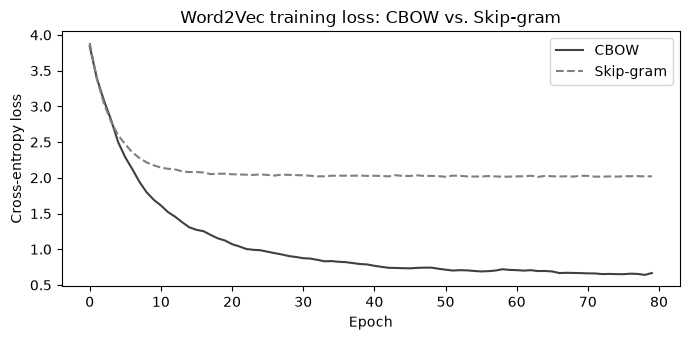

In [10]:
# [RUN] — plot training curves

fig_training, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(cbow_losses, label='CBOW', color='#404040')
ax.plot(skipgram_losses, label='Skip-gram', color='#808080', linestyle='--')
ax.set_xlabel('Epoch')
ax.set_ylabel('Cross-entropy loss')
ax.set_title('Word2Vec training loss: CBOW vs. Skip-gram')
ax.legend()
plt.tight_layout()
plt.show()

### 2.5 — Extract and compare embeddings

In [11]:
def get_embedding(model, word, word2idx):
    """Return the embedding vector for a word as a numpy array.

    Args:
        model    (nn.Module):     Trained Word2Vec model with .embeddings layer.
        word     (str):           Target word.
        word2idx (dict[str,int]): Word-to-index mapping.

    Returns:
        np.ndarray: 1D embedding vector of shape (embed_dim,).

    Raises:
        KeyError: If word is not in word2idx.
    """
    if word not in word2idx:
        raise KeyError(f"'{word}' is not in the vocabulary")
    # copy() detaches the result from the parameter storage that training updates.
    return model.embeddings.weight[word2idx[word]].detach().cpu().numpy().copy()


def top_similar_words(model, word, word2idx, idx2word, n=5):
    """Return the n most similar words to a query word by cosine similarity.

    Excludes the query word itself from results.

    Args:
        model    (nn.Module):       Trained Word2Vec model.
        word     (str):             Query word.
        word2idx (dict[str, int]):  Word-to-index mapping.
        idx2word (dict[int, str]):  Index-to-word mapping.
        n        (int):             Number of results to return.

    Returns:
        list[tuple[str, float]]: [(word, similarity), ...] sorted descending.
    """
    if not isinstance(n, int) or n < 1:
        raise ValueError(f"n must be a positive int, got {n!r}")
    query_vec = get_embedding(model, word, word2idx)
    # Candidates are looked up by word through word2idx, so rows cannot misalign.
    scored = [(cand, cosine_similarity(query_vec, get_embedding(model, cand, word2idx)))
              for cand in idx2word.values() if cand != word]
    # Highest similarity first; ties broken alphabetically for a stable order.
    scored.sort(key=lambda item: (-item[1], item[0]))
    return scored[:n]


IDX2WORD = {i: w for w, i in WORD2IDX.items()}

# Named output variables for the autograder
# Cosine similarity between known-related pairs from each model
cbow_sim_cat_dog      = cosine_similarity(
    get_embedding(cbow_model, 'cat', WORD2IDX),
    get_embedding(cbow_model, 'dog', WORD2IDX))
skipgram_sim_cat_dog  = cosine_similarity(
    get_embedding(skipgram_model, 'cat', WORD2IDX),
    get_embedding(skipgram_model, 'dog', WORD2IDX))
cbow_sim_cat_model    = cosine_similarity(
    get_embedding(cbow_model, 'cat', WORD2IDX),
    get_embedding(cbow_model, 'model', WORD2IDX))
skipgram_sim_cat_model = cosine_similarity(
    get_embedding(skipgram_model, 'cat', WORD2IDX),
    get_embedding(skipgram_model, 'model', WORD2IDX))

print(f"{'Pair':<25s} {'CBOW':>8s}  {'Skip-gram':>10s}")
print("-" * 46)
print(f"{'sim(cat, dog)':<25s} {cbow_sim_cat_dog:>8.4f}  {skipgram_sim_cat_dog:>10.4f}")
print(f"{'sim(cat, model)':<25s} {cbow_sim_cat_model:>8.4f}  {skipgram_sim_cat_model:>10.4f}")

print(f"\nTop-5 similar to 'team' — CBOW:")
for w, s in top_similar_words(cbow_model, 'team', WORD2IDX, IDX2WORD):
    print(f"  {w:<15s} {s:.4f}")
print(f"\nTop-5 similar to 'team' — Skip-gram:")
for w, s in top_similar_words(skipgram_model, 'team', WORD2IDX, IDX2WORD):
    print(f"  {w:<15s} {s:.4f}")

Pair                          CBOW   Skip-gram
----------------------------------------------
sim(cat, dog)               0.2901      0.1785
sim(cat, model)             0.3195      0.1013

Top-5 similar to 'team' — CBOW:
  chef            0.3800
  hid             0.3665
  with            0.3306
  model           0.3242
  dog             0.3019

Top-5 similar to 'team' — Skip-gram:
  model           0.3215
  during          0.2773
  match           0.2603
  bird            0.2574
  neural          0.2317


### 2.6 — Reflection (manually graded, 6 pts)

**Prompt:** Answer both questions in 4–6 sentences total.

**Question A:** CBOW averages context embeddings before predicting the center word; Skip-gram uses the center embedding to predict each context word independently. Based on the training curves and similarity results above, describe one concrete difference you observe between the two models' outputs. Explain the architectural reason for that difference.

**Question B:** Both models use the same embedding matrix size and the same corpus. If you needed to choose one for a downstream task involving rare domain-specific terminology (e.g., clinical notes), which would you choose and why?

**Your reflection:**

**A.** CBOW ends at a cross-entropy of 0.6675, while Skip-gram's curve levels off just above 2 and ends at 2.0221. CBOW conditions on the whole context window, and in this 40-sentence corpus most windows occur with only one center word, so its loss keeps falling as it memorizes windows; Skip-gram predicts each context word from the center alone, and a center such as *the* has many different neighbors, so its loss cannot fall below the conditional entropy of a context given its center. The lower loss does not give better geometry: CBOW rates *cat–model* (0.3195) above *cat–dog* (0.2901), whereas Skip-gram orders them as expected (0.1785 vs. 0.1013).

**B.** I would choose Skip-gram, because each occurrence of a rare term as a center yields up to 2 × window separate predictions that each send a full gradient to the term's own vector, whereas CBOW averages the term with its neighbors, so each update to its vector is scaled by 1/k for a window of k context words and shared with those words. On identical data here only Skip-gram separates *cat–dog* from *cat–model*, although both models' vectors stay close to their random N(0, 1) initialization after 80 epochs on 418 pairs, so the margins are small. For a clinical vocabulary of tens of thousands of types I would also replace the full softmax used here, whose cost per prediction grows with the vocabulary size V, with negative sampling, which makes the cost of each (center, context) pair independent of V.

---

## Part 3 — GloVe: Similarity and Analogy Evaluation (18 points)

Training Word2Vec on 40 sentences produces interpretable but limited embeddings. Pre-trained GloVe vectors (Pennington et al., 2014), trained on billions of tokens from Common Crawl and Wikipedia, encode far richer semantic and syntactic relationships.

In this part you will load pre-trained GloVe-100 vectors via `gensim.downloader` and evaluate them on two standard benchmarks: a word similarity task (Spearman correlation with human judgments) and a word analogy task (vector arithmetic accuracy).

**Note:** Downloading GloVe vectors requires an internet connection and ~130MB of disk space. The download is cached after the first run.

In [12]:
# [RUN] — load pre-trained GloVe 100-dimensional vectors
# This cell may take 1-2 minutes on first run (download ~130MB)

print("Loading GloVe-100 vectors (this may take a moment)...")
glove = gensim_api.load("glove-wiki-gigaword-100")
print(f"GloVe loaded: {len(glove):,} words, {glove.vector_size}-dimensional vectors")

Loading GloVe-100 vectors (this may take a moment)...


GloVe loaded: 400,000 words, 100-dimensional vectors


### 3.1 — Word similarity evaluation

A standard way to evaluate word embeddings is to compare cosine similarities against human similarity judgments. We use a small curated set of word pairs with human-assigned similarity scores (scale 0–10). A good embedding model should rank pairs in the same order as humans do; Spearman rank correlation quantifies this.

In [13]:
# Word similarity pairs: (word1, word2, human_score_0_to_10)
# Drawn from the WordSim-353 and SimLex-999 benchmark style
SIMILARITY_PAIRS = [
    ('cat',      'dog',      8.5),
    ('computer', 'software', 8.0),
    ('football', 'soccer',   9.1),
    ('bread',    'butter',   7.2),
    ('king',     'queen',    7.8),
    ('car',      'train',    6.3),
    ('doctor',   'hospital', 7.0),
    ('happy',    'joyful',   9.0),
    ('table',    'chair',    6.5),
    ('river',    'ocean',    6.8),
    ('cat',      'computer', 1.8),
    ('football', 'recipe',   0.9),
    ('king',     'cabbage',  0.5),
    ('bread',    'engine',   0.7),
    ('music',    'algebra',  1.5),
]


def evaluate_similarity(glove_model, pairs):
    """Evaluate GloVe similarity against human judgments.

    For each pair where both words are in the GloVe vocabulary, compute
    cosine similarity. Return the model scores, human scores, and
    Spearman rank correlation between them.

    Args:
        glove_model: Loaded gensim KeyedVectors model.
        pairs (list[tuple]): (word1, word2, human_score) triples.

    Returns:
        tuple:
            human_scores  (list[float]): Human scores for covered pairs.
            model_scores  (list[float]): Cosine similarities for covered pairs.
            spearman_rho  (float):       Spearman correlation.
            coverage      (float):       Fraction of pairs covered by vocabulary.
    """
    if len(pairs) == 0:
        raise ValueError("pairs is empty")
    # Same membership test and order as the printing loop below, so rows align.
    covered = [(w1, w2, float(h)) for w1, w2, h in pairs
               if w1 in glove_model and w2 in glove_model]
    human_scores = [h for _, _, h in covered]
    model_scores = [cosine_similarity(glove_model[w1], glove_model[w2])
                    for w1, w2, _ in covered]
    coverage = len(covered) / len(pairs)
    # Spearman's rho is undefined for fewer than two pairs; return NaN rather than
    # a misleading value.
    if len(covered) < 2:
        return human_scores, model_scores, float('nan'), coverage
    rho, _ = spearmanr(human_scores, model_scores)
    return human_scores, model_scores, float(rho), coverage


human_scores, model_scores, similarity_rho, similarity_coverage = \
    evaluate_similarity(glove, SIMILARITY_PAIRS)

print(f"Similarity evaluation:")
print(f"  Pairs evaluated:    {len(human_scores)} / {len(SIMILARITY_PAIRS)}")
print(f"  Vocabulary coverage: {similarity_coverage:.1%}")
print(f"  Spearman rho:        {similarity_rho:.4f}")
print()
print(f"  {'Pair':<25s} {'Human':>6s}  {'GloVe':>6s}")
print("  " + "-"*40)
for (w1, w2, h), m in zip(
        [(p[0],p[1],p[2]) for p in SIMILARITY_PAIRS
         if p[0] in glove and p[1] in glove],
        model_scores):
    print(f"  {w1+' — '+w2:<25s} {h:>6.1f}  {m:>6.4f}")

Similarity evaluation:
  Pairs evaluated:    15 / 15
  Vocabulary coverage: 100.0%
  Spearman rho:        0.8750

  Pair                       Human   GloVe
  ----------------------------------------
  cat — dog                    8.5  0.8798
  computer — software          8.0  0.8373
  football — soccer            9.1  0.8732
  bread — butter               7.2  0.7280
  king — queen                 7.8  0.7508
  car — train                  6.3  0.6823
  doctor — hospital            7.0  0.6901
  happy — joyful               9.0  0.5260
  table — chair                6.5  0.4925
  river — ocean                6.8  0.5743
  cat — computer               1.8  0.2975
  football — recipe            0.9  0.0564
  king — cabbage               0.5  0.0384
  bread — engine               0.7  0.0723
  music — algebra              1.5  0.1308


### 3.2 — Word analogy evaluation

Mikolov et al. showed that GloVe embeddings support analogy reasoning via vector arithmetic:

$$\vec{\text{king}} - \vec{\text{man}} + \vec{\text{woman}} \approx \vec{\text{queen}}$$

The standard evaluation finds the word whose vector is closest to `b⃗ − a⃗ + c⃗`, excluding the three query words from the candidates.

In [14]:
def solve_analogy(glove_model, a, b, c, n=5):
    """Solve the analogy a:b :: c:? using GloVe vector arithmetic.

    Computes target = vec(b) - vec(a) + vec(c), then finds the n words
    with highest cosine similarity to target, excluding a, b, and c.

    Args:
        glove_model: Loaded gensim KeyedVectors model.
        a, b, c (str): Analogy words. All three must be in the vocabulary.
        n       (int): Number of candidates to return.

    Returns:
        list[tuple[str, float]]: [(word, similarity), ...] or empty list
                                  if any query word is not in vocabulary.
    """
    if not isinstance(n, int) or n < 1:
        raise ValueError(f"n must be a positive int, got {n!r}")
    query_words = (a, b, c)
    if any(w not in glove_model for w in query_words):
        return []
    # Standard 3CosAdd: each input is normalized to unit length before combining,
    # as gensim's most_similar does, so no single long vector dominates the target.
    target = (glove_model.get_vector(b, norm=True) - glove_model.get_vector(a, norm=True)
              + glove_model.get_vector(c, norm=True))
    if not np.any(target):
        raise ValueError("b - a + c is the zero vector; cosine similarity is undefined")
    # similar_by_vector ranks all 400k words by cosine to target in one vectorized
    # pass (a cosine_similarity loop would be 400k Python calls per query).
    # Request n + 3 so that n candidates remain after a, b, c are removed.
    candidates = glove_model.similar_by_vector(target, topn=n + len(query_words))
    return [(w, float(s)) for w, s in candidates if w not in query_words][:n]


# Analogy benchmark
ANALOGY_TESTS = [
    # (a,          b,         c,          expected_answer)
    ('man',     'king',    'woman',    'queen'),
    ('paris',   'france',  'berlin',   'germany'),
    ('good',    'better',  'bad',      'worse'),
    ('walk',    'walked',  'run',      'ran'),
    ('cat',     'cats',    'dog',      'dogs'),
    ('tall',    'taller',  'fast',     'faster'),
    ('man',     'actor',   'woman',    'actress'),
    ('france',  'french',  'germany',  'german'),
]

print(f"{'Analogy':<40s} {'Expected':>10s}  {'Top-1':>10s}  {'Correct':>8s}")
print("-" * 73)

analogy_results = []
for a, b, c, expected in ANALOGY_TESTS:
    results = solve_analogy(glove, a, b, c, n=5)
    if not results:
        print(f"{a}:{b} :: {c}:?  — OOV")
        continue
    top1_word, top1_sim = results[0]
    correct = (top1_word.lower() == expected.lower())
    analogy_results.append(correct)
    label = '✓' if correct else '✗'
    print(f"{a+':'+b+' :: '+c+':?':<40s} {expected:>10s}  {top1_word:>10s}  {label:>8s}")

# Named output variable
analogy_accuracy = sum(analogy_results) / len(analogy_results) if analogy_results else 0.0
print(f"\nAnalogy accuracy: {analogy_accuracy:.1%}  ({sum(analogy_results)}/{len(analogy_results)})")

Analogy                                    Expected       Top-1   Correct
-------------------------------------------------------------------------
man:king :: woman:?                           queen       queen         ✓
paris:france :: berlin:?                    germany     germany         ✓
good:better :: bad:?                          worse       worse         ✓
walk:walked :: run:?                            ran        went         ✗
cat:cats :: dog:?                              dogs        dogs         ✓
tall:taller :: fast:?                        faster      faster         ✓
man:actor :: woman:?                        actress     actress         ✓
france:french :: germany:?                   german      german         ✓

Analogy accuracy: 87.5%  (7/8)


### 3.3 — Reflection (manually graded, 6 pts)

**Prompt:** Answer both questions in 4–6 sentences total.

**Question A:** Look at the analogy results above. Pick one **failed** analogy and explain concretely why the vector arithmetic might have failed. Consider what the training corpus of GloVe (Common Crawl + Wikipedia) would encode about those words, and how that could misalign with the expected answer.

**Question B:** GloVe's Spearman correlation with human similarity judgments is typically high for antonyms (e.g., *hot–cold*) but these pairs receive low scores from humans. Explain what this reveals about what cosine similarity in embedding space actually measures, and why it differs from human intuitions about similarity.

**Your reflection:**

**A.** The analogy *walk:walked :: run:?* returned *went* instead of *ran*, the only miss behind the 87.5% (7/8) accuracy. The offset walked − walk encodes the regular *-ed* past tense, but *ran* is an irregular form, and nothing in GloVe's log-bilinear objective forces ran − run to be parallel to that offset. The glove-wiki-gigaword-100 vectors were trained on Wikipedia 2014 and Gigaword 5 (not Common Crawl), and in Gigaword newswire *run* also means running for office or scoring runs in baseball, so its single vector mixes senses and the normalized b − a + c lands among frequent past-tense verbs, where *went*, more frequent than *ran* in the GloVe training text, scores highest.

**B.** Correcting the premise, GloVe's cosine similarity (not its Spearman correlation) is high for antonyms such as *hot–cold*, because the cosine between two GloVe word vectors is a second-order measure: it is high when the two words have similar rows in the log co-occurrence matrix that GloVe factorizes, and antonyms occur in many of the same contexts. SimLex-style ratings reward synonymy, and the curated pairs here, scored in the style of WordSim-353 and SimLex-999 rather than taken from those benchmarks, show the reverse mismatch: *happy–joyful* gets the second-highest human score (9.0) but a cosine of only 0.5260, below *bread–butter* (0.7280) and *car–train* (0.6823), because the rarer *joyful* shares fewer contexts with *happy* than these topically linked pairs share with each other. The Spearman ρ of 0.8750 is high because the set pairs related items (human scores 6.3–9.1) with unrelated ones (0.5–1.8) and contains no antonyms, so it overstates GloVe's fitness for tasks that need synonymy, such as query expansion, where *cold* would be retrieved as a substitute for *hot*.

---

## Part 4 — Dimensionality Reduction and Visualization (13 points)

Word embeddings live in 50–300 dimensional spaces that humans cannot directly inspect. Dimensionality reduction to 2D reveals geometric structure — clusters, directions, and relative positions — that is invisible in high dimensions.

We use **PCA** for the primary student implementation because it is deterministic and the principal components are interpretable. You will also run a [RUN] cell with t-SNE for comparison.

### 4.1 — PCA projection

In [15]:
def pca_2d(embedding_matrix):
    """Project an embedding matrix to 2D using PCA.

    Centers the matrix (subtract column means) and returns the projection
    onto the first two principal components using SVD.

    Args:
        embedding_matrix (np.ndarray): Shape (n_words, embed_dim).

    Returns:
        np.ndarray: Shape (n_words, 2) — 2D coordinates.
    """
    X = np.asarray(embedding_matrix, dtype=np.float64)
    if X.ndim != 2 or min(X.shape) < 2:
        raise ValueError(f"expected a 2D matrix with at least 2 rows and 2 columns, got shape {X.shape}")
    if not np.all(np.isfinite(X)):
        raise ValueError("embedding_matrix contains NaN or inf")
    centered = X - X.mean(axis=0)                              # 1. center each dimension
    U, S, _ = np.linalg.svd(centered, full_matrices=False)     # 2. X = U S Vt
    return U[:, :2] * S[:2]                                    # 3. coordinates on PC1, PC2


# Build embedding matrix for our trained vocabulary (Skip-gram)
def get_embedding_matrix(model, word2idx):
    """Extract the full embedding matrix from a trained Word2Vec model.

    Args:
        model    (nn.Module):     Trained Word2Vec model with .embeddings layer.
        word2idx (dict[str,int]): Word-to-index mapping.

    Returns:
        np.ndarray: Shape (vocab_size, embed_dim).
    """
    if sorted(word2idx.values()) != list(range(len(word2idx))):
        raise ValueError("word2idx values must be exactly 0..V-1 so rows align with the vocabulary")
    words_by_index = sorted(word2idx, key=word2idx.get)
    return np.stack([get_embedding(model, w, word2idx) for w in words_by_index])


skipgram_embeddings = get_embedding_matrix(skipgram_model, WORD2IDX)
coords_2d = pca_2d(skipgram_embeddings)

print(f"Embedding matrix shape:   {skipgram_embeddings.shape}")
print(f"PCA projection shape:     {coords_2d.shape}")
print(f"PC1 range: [{coords_2d[:, 0].min():.3f}, {coords_2d[:, 0].max():.3f}]")
print(f"PC2 range: [{coords_2d[:, 1].min():.3f}, {coords_2d[:, 1].max():.3f}]")

Embedding matrix shape:   (46, 50)
PCA projection shape:     (46, 2)
PC1 range: [-4.991, 5.404]
PC2 range: [-5.213, 3.729]


### 4.2 — Visualize with cluster labels

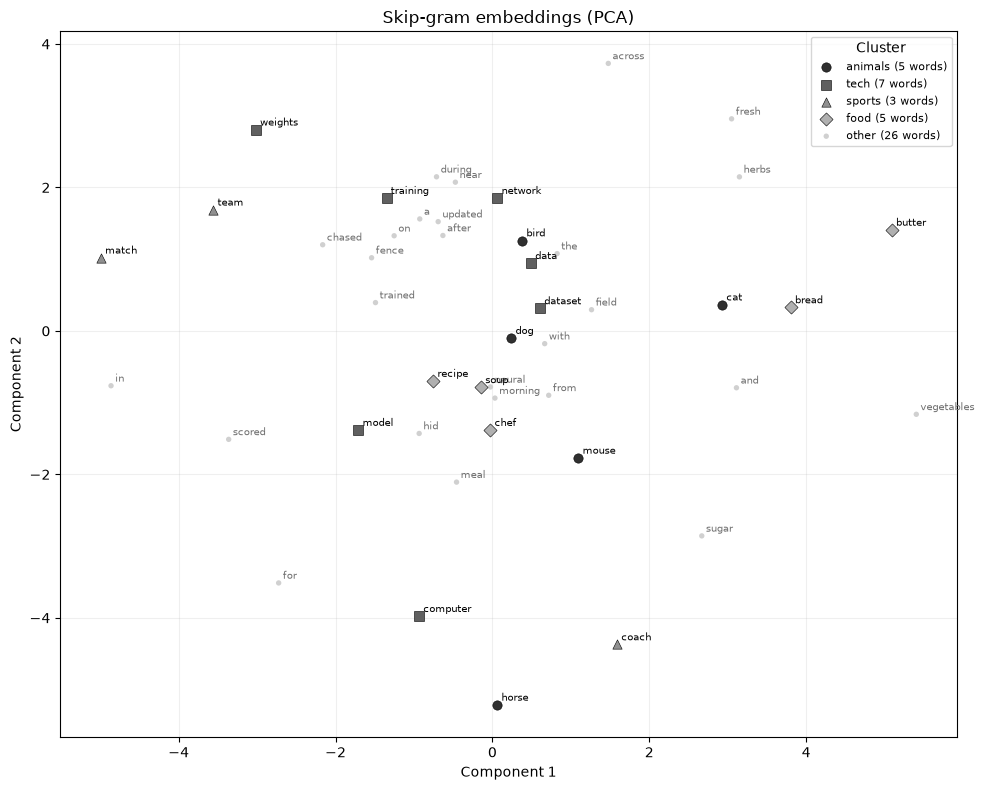

In [16]:
# Semantic cluster labels for the corpus vocabulary
CLUSTER_LABELS = {
    'cat': 'animals',   'dog': 'animals',   'bird': 'animals',
    'horse': 'animals', 'rabbit': 'animals', 'mouse': 'animals',
    'computer': 'tech', 'model': 'tech',     'data': 'tech',
    'network': 'tech',  'algorithm': 'tech', 'software': 'tech',
    'dataset': 'tech',  'training': 'tech',  'weights': 'tech',
    'team': 'sports',   'coach': 'sports',   'player': 'sports',
    'match': 'sports',  'goal': 'sports',    'ball': 'sports',
    'game': 'sports',   'score': 'sports',
    'chef': 'food',     'bread': 'food',     'soup': 'food',
    'recipe': 'food',   'flour': 'food',     'butter': 'food',
}
CLUSTER_STYLES = {
    'animals': ('o', '#303030'),
    'tech':    ('s', '#606060'),
    'sports':  ('^', '#909090'),
    'food':    ('D', '#b0b0b0'),
    'other':   ('.', '#d0d0d0'),
}


def plot_embeddings_2d(coords_2d, vocab, cluster_labels, cluster_styles,
                       title="Skip-gram embeddings (PCA)", annotate=True):
    """Plot 2D word embeddings coloured by semantic cluster.

    Args:
        coords_2d      (np.ndarray):       Shape (n_words, 2).
        vocab          (list[str]):        Word list aligned with coords_2d.
        cluster_labels (dict[str, str]):   word -> cluster name.
        cluster_styles (dict[str, tuple]): cluster -> (marker, colour).
        title          (str):              Plot title.
        annotate       (bool):             If True, label each point.

    Returns:
        tuple: (fig, ax) matplotlib objects.
    """
    coords_2d = np.asarray(coords_2d)
    if coords_2d.ndim != 2 or coords_2d.shape != (len(vocab), 2):
        raise ValueError(f"coords_2d must have shape ({len(vocab)}, 2), got {coords_2d.shape}")
    # Words without a label fall back to the 'other' style.
    clusters = [cluster_labels.get(w, 'other') for w in vocab]
    missing = sorted(set(clusters) - set(cluster_styles))
    if missing:
        raise KeyError(f"cluster_styles has no entry for cluster(s): {missing}")

    fig, ax = plt.subplots(figsize=(10, 8))
    # One series per cluster, in cluster_styles order, so the legend order is fixed.
    for cluster, (marker, color) in cluster_styles.items():
        rows = [i for i, c in enumerate(clusters) if c == cluster]
        if not rows:
            continue
        is_other = cluster == 'other'
        ax.scatter(coords_2d[rows, 0], coords_2d[rows, 1], marker=marker, color=color,
                   s=60 if is_other else 45, edgecolors='none' if is_other else 'black',
                   linewidths=0.4, zorder=2 if is_other else 3,
                   label=f"{cluster} ({len(rows)} words)")
    if annotate:
        for word, cluster, (x, y) in zip(vocab, clusters, coords_2d):
            ax.annotate(word, (x, y), xytext=(3, 3), textcoords='offset points', fontsize=7,
                        color='#707070' if cluster == 'other' else 'black')

    ax.set_title(title)
    ax.set_xlabel('Component 1')
    ax.set_ylabel('Component 2')
    ax.grid(True, alpha=0.2)
    ax.legend(title='Cluster', fontsize=8, loc='best')
    fig.tight_layout()
    return fig, ax


fig_embeddings, ax_embeddings = plot_embeddings_2d(
    coords_2d, VOCAB, CLUSTER_LABELS, CLUSTER_STYLES)
plt.show()

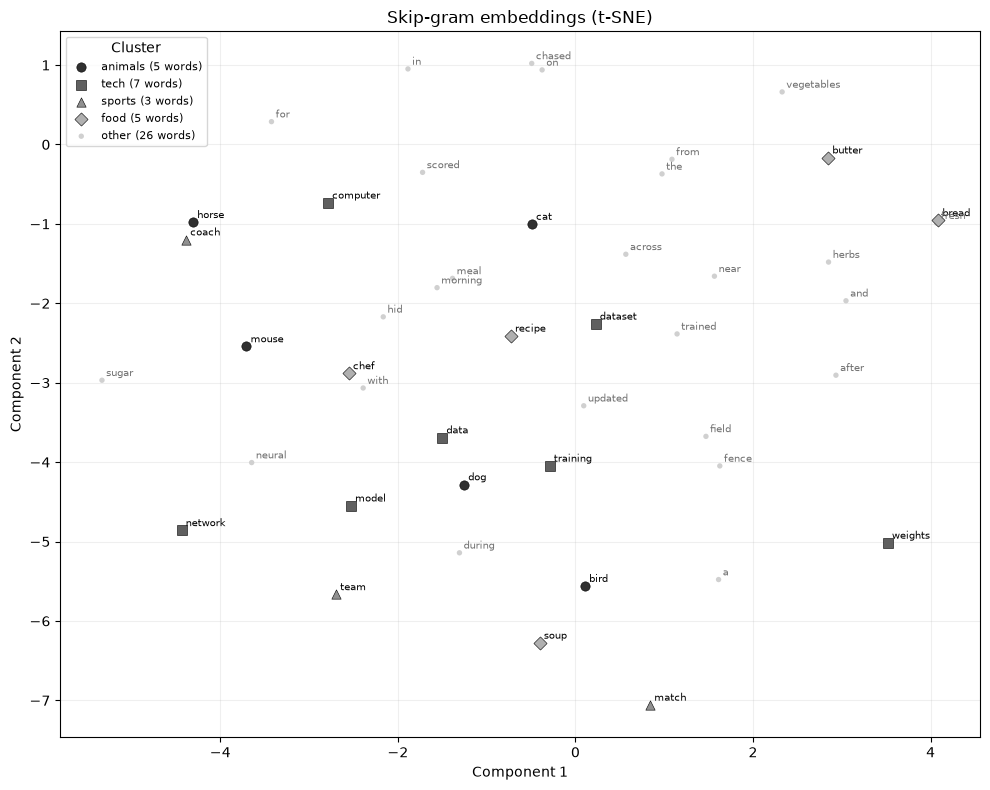

In [17]:
# [RUN] — t-SNE comparison (non-deterministic; run for comparison only)

from sklearn.manifold import TSNE

tsne = TSNE(n_components=2, perplexity=15, random_state=42, max_iter=1000)
coords_tsne = tsne.fit_transform(skipgram_embeddings)

fig_tsne, ax_tsne = plot_embeddings_2d(
    coords_tsne, VOCAB, CLUSTER_LABELS, CLUSTER_STYLES,
    title="Skip-gram embeddings (t-SNE)")
plt.show()

### 4.3 — Reflection (manually graded, 6 pts)

**Prompt:** Answer both questions in 4–6 sentences total.

**Question A:** Look at the PCA plot. Identify one specific geometric structure — a cluster, a direction, or a relative positioning of words — and explain what semantic or syntactic property it encodes. Be specific: name the words and describe their spatial arrangement.

**Question B:** PCA and t-SNE often produce different layouts from the same embedding matrix. Explain the key algorithmic difference between the two methods and identify one type of geometric structure that t-SNE preserves better than PCA, and one type that PCA preserves better.

**Your reflection:**

**A.** The most visible structure in the PCA plot is the group at the positive end of PC1: *vegetables* and *butter* are the two rightmost points, and *bread*, *herbs*, *fresh*, *sugar* and the conjunction *and* lie at the same end, joined only by *cat*. Most of these words are each other's window-2 contexts in coordinated lists such as "fresh vegetables and herbs" and "butter and sugar", so a learned version of this group would encode membership in a coordination, which is a syntactic property. The evidence that training produced it is thin: Skip-gram rates the same-cluster pair *cat–dog* at only 0.1785 against 0.1013 for *cat–model*, and projecting the untrained N(0, 1) vectors onto the same axis already places most of this group at its positive end, so much of the arrangement comes from initialization.

**B.** PCA is a linear orthogonal projection onto the two directions of maximum variance (the top right singular vectors of the centered matrix), whereas t-SNE turns pairwise distances into neighbor probabilities, with Gaussian bandwidths set by the perplexity of 15, and places the points in 2D to minimize the KL divergence to a heavy-tailed Student-t neighbor distribution. t-SNE preserves local neighborhoods better: *horse* and *coach* are mutual nearest neighbors in the 50-dimensional space, and t-SNE draws them as an adjacent pair, while PCA puts *horse* at the PC2 minimum (−5.213) with a visible gap to *coach*. PCA preserves global structure better, because each 2D displacement is the orthogonal projection of the 50-dimensional displacement, so plotted distances never exceed the true ones and the PC1 span of 5.404 − (−4.991) = 10.395 between the two outermost words is a lower bound on their true distance, while t-SNE's distances between non-neighbors and the relative placement of its groups carry no such guarantee.

---

## Part 5 — Bias in Word Embeddings (20 points)

Word embeddings learn from human-generated text and therefore absorb the statistical regularities of that text — including its social biases. Bolukbasi et al. (2016) showed that GloVe and Word2Vec encode stereotypical gender associations: *programmer* is closer to *man*, *homemaker* is closer to *woman*. Caliskan et al. (2017) introduced the **Word Embedding Association Test (WEAT)** to quantify this.

WEAT borrows its structure from the Implicit Association Test (IAT) from psychology. Two sets of **target words** (e.g., career words vs. family words) are tested against two sets of **attribute words** (e.g., male names vs. female names). The **effect size** $d$ measures how strongly the attributes associate with one target category over the other:

$$d = \frac{\text{mean}_{w \in A}\, s(w, T_1, T_2) - \text{mean}_{w \in B}\, s(w, T_1, T_2)}{\text{std}_{w \in A \cup B}\, s(w, T_1, T_2)}$$

where the association of a word $w$ with target sets $T_1$ and $T_2$ is:

$$s(w, T_1, T_2) = \text{mean}_{t \in T_1}\cos(w, t) - \text{mean}_{t \in T_2}\cos(w, t)$$

An effect size near 0 indicates no association; $d > 1.0$ indicates a strong bias in the direction of attribute set A; $d < -1.0$ indicates strong bias toward B.

### 5.1 — Implement WEAT

In [18]:
def word_association(word_vec, target1_vecs, target2_vecs):
    """Compute the differential association of a word with two target sets.

    s(w, T1, T2) = mean_{t in T1} cos(w, t) - mean_{t in T2} cos(w, t)

    Args:
        word_vec      (np.ndarray):       Embedding of the query word.
        target1_vecs  (list[np.ndarray]): Embeddings of target set T1.
        target2_vecs  (list[np.ndarray]): Embeddings of target set T2.

    Returns:
        float: Differential association score.
    """
    if len(target1_vecs) == 0 or len(target2_vecs) == 0:
        raise ValueError("both target sets need at least one vector")
    mean_t1 = np.mean([cosine_similarity(word_vec, t) for t in target1_vecs])
    mean_t2 = np.mean([cosine_similarity(word_vec, t) for t in target2_vecs])
    return float(mean_t1 - mean_t2)


def weat_effect_size(A_vecs, B_vecs, T1_vecs, T2_vecs):
    """Compute WEAT effect size d.

    d = (mean_{w in A} s(w,T1,T2) - mean_{w in B} s(w,T1,T2))
        / std_{w in A+B} s(w,T1,T2)

    A positive d means attribute set A is more associated with T1
    relative to attribute set B.

    Args:
        A_vecs  (list[np.ndarray]): Embeddings for attribute set A.
        B_vecs  (list[np.ndarray]): Embeddings for attribute set B.
        T1_vecs (list[np.ndarray]): Embeddings for target set T1.
        T2_vecs (list[np.ndarray]): Embeddings for target set T2.

    Returns:
        float: WEAT effect size. Returns 0.0 if std is zero.
    """
    if len(A_vecs) == 0 or len(B_vecs) == 0:
        raise ValueError("both attribute sets need at least one vector")
    assoc_A = [word_association(w, T1_vecs, T2_vecs) for w in A_vecs]
    assoc_B = [word_association(w, T1_vecs, T2_vecs) for w in B_vecs]
    # Caliskan et al. (2017) take the std-dev over the paper's targets X ∪ Y (this
    # notebook's attribute sets A ∪ B) without stating sample or population. ddof=0
    # (population) matches the WEFE and responsibly code and footnote 2 of the arXiv
    # version (1608.07187v4), which gives 2.0 as the maximum effect size; for two
    # equal-size sets only the population std can reach that bound.
    std = np.std(assoc_A + assoc_B, ddof=0)
    # A tolerance, because identical scores can leave a std of ~1e-17 instead of 0.
    if std < 1e-12:
        return 0.0
    return float((np.mean(assoc_A) - np.mean(assoc_B)) / std)

### 5.2 — Run WEAT on GloVe

We test two standard word sets from Caliskan et al. (2017):

- **WEAT 6:** Career vs. Family × Male names vs. Female names
- **WEAT 7:** Math vs. Arts × Male names vs. Female names

In [19]:
# WEAT word sets (Caliskan et al., 2017, Table 1)

# Target sets
CAREER_WORDS = ['executive', 'management', 'professional', 'corporation',
                'salary', 'office', 'business', 'career']
FAMILY_WORDS = ['home', 'parents', 'children', 'family',
                'cousins', 'marriage', 'wedding', 'relatives']
MATH_WORDS   = ['math', 'algebra', 'geometry', 'calculus',
                'equations', 'computation', 'numbers', 'addition']
ARTS_WORDS   = ['poetry', 'art', 'dance', 'literature',
                'novel', 'symphony', 'drama', 'sculpture']

# Attribute sets
MALE_NAMES   = ['john', 'paul', 'mike', 'kevin', 'steve',
                'greg', 'jeff', 'bill']
FEMALE_NAMES = ['amy', 'joan', 'lisa', 'sarah', 'diana',
                'kate', 'ann', 'donna']


def get_glove_vecs(glove_model, words):
    """Return GloVe vectors for words present in the vocabulary.

    Args:
        glove_model: Loaded gensim KeyedVectors model.
        words (list[str]): Target words.

    Returns:
        list[np.ndarray]: Vectors for words found in the vocabulary.
    """
    if isinstance(words, str):
        raise TypeError("words must be a list of strings, not a single string")
    missing = [w for w in words if w not in glove_model]
    if missing:
        # Warnings are silenced in the setup cell, so dropped words are printed.
        print(f"get_glove_vecs: {len(missing)} of {len(words)} words not in vocabulary: {missing}")
    return [glove_model[w] for w in words if w in glove_model]


# Retrieve vectors
career_vecs = get_glove_vecs(glove, CAREER_WORDS)
family_vecs = get_glove_vecs(glove, FAMILY_WORDS)
math_vecs   = get_glove_vecs(glove, MATH_WORDS)
arts_vecs   = get_glove_vecs(glove, ARTS_WORDS)
male_vecs   = get_glove_vecs(glove, MALE_NAMES)
female_vecs = get_glove_vecs(glove, FEMALE_NAMES)

# Named output variables
weat6_effect_size = weat_effect_size(male_vecs, female_vecs,
                                      career_vecs, family_vecs)
weat7_effect_size = weat_effect_size(male_vecs, female_vecs,
                                      math_vecs, arts_vecs)

print("WEAT results on GloVe-100:")
print(f"  WEAT 6 (Career/Family × Male/Female names): d = {weat6_effect_size:.4f}")
print(f"  WEAT 7 (Math/Arts   × Male/Female names): d = {weat7_effect_size:.4f}")
print()
print("Interpretation:")
print("  d > 0: male names more associated with first target set (career / math)")
print("  d < 0: female names more associated with first target set")
print("  |d| > 1.0 indicates strong bias; |d| > 0.5 moderate bias")

WEAT results on GloVe-100:
  WEAT 6 (Career/Family × Male/Female names): d = 1.7741
  WEAT 7 (Math/Arts   × Male/Female names): d = 1.5945

Interpretation:
  d > 0: male names more associated with first target set (career / math)
  d < 0: female names more associated with first target set
  |d| > 1.0 indicates strong bias; |d| > 0.5 moderate bias


### 5.3 — Closest associates for individual words

In [20]:
# [RUN] — examine individual word associations

probe_words = ['programmer', 'nurse', 'engineer', 'teacher',
               'executive', 'secretary']

print(f"{'Word':<14s}  {'Closest male name':>18s}  {'Closest female name':>20s}  {'Δ (M-F)':>8s}")
print("-" * 68)
for word in probe_words:
    if word not in glove:
        continue
    wv = glove[word]
    male_sims   = [(n, cosine_similarity(wv, glove[n]))
                   for n in MALE_NAMES if n in glove]
    female_sims = [(n, cosine_similarity(wv, glove[n]))
                   for n in FEMALE_NAMES if n in glove]
    best_male   = max(male_sims, key=lambda x: x[1])
    best_female = max(female_sims, key=lambda x: x[1])
    mean_male   = np.mean([s for _, s in male_sims])
    mean_female = np.mean([s for _, s in female_sims])
    print(f"{word:<14s}  {best_male[0]+' ('+f"{best_male[1]:.3f})":>18s}  "
          f"{best_female[0]+' ('+f"{best_female[1]:.3f})":>20s}  "
          f"{mean_male - mean_female:>+8.4f}")

Word             Closest male name   Closest female name   Δ (M-F)
--------------------------------------------------------------------
programmer            jeff (0.332)          lisa (0.228)   +0.1485
nurse                 greg (0.312)           ann (0.453)   -0.1205
engineer              john (0.440)           ann (0.272)   +0.1478
teacher               paul (0.401)         sarah (0.406)   -0.0032
executive             paul (0.556)           ann (0.425)   +0.1913
secretary             john (0.534)         donna (0.398)   +0.1131


### 5.4 — Reflection (manually graded, 6 pts)

**Prompt:** Answer both questions in 4–6 sentences total.

**Question A:** The WEAT effect sizes you computed are not opinions — they are geometric properties of vectors trained on a large corpus. Explain the causal chain from *biased training data* to *biased model output* to *biased downstream prediction*, using a concrete NLP application (e.g., résumé screening, coreference resolution, or machine translation) as your example.

**Question B:** One response to embedding bias is *debiasing* — geometrically projecting out the gender direction (Bolukbasi et al., 2016). Identify one concrete limitation of this approach: something it cannot remove, or a way it could introduce a different problem. Use the WEAT framework or the word associations above to support your argument.

**Your reflection:**

**A.** GloVe fits its vectors to log co-occurrence counts from Wikipedia and Gigaword newswire, so wherever that text pairs male first names with business vocabulary and female first names with family vocabulary, the pattern becomes geometry: WEAT 6 gives d = 1.7741, and *executive* is on average 0.1913 more cosine-similar to the male names than to the female names. A résumé screener that represents each résumé as the mean of its GloVe vectors and ranks candidates by cosine similarity to an executive job description inherits that offset, so two résumés identical except for the name *John* or *Amy* receive different scores, and a classifier trained on past hiring decisions can learn the name-linked component as a predictor and reproduce the historical skew in who was hired.

**B.** Hard debiasing (Bolukbasi et al., 2016) removes, from every word it treats as gender-neutral, the component along one gender direction g defined from pairs such as *he–she*. Once *executive* is orthogonal to g, its Δ(M−F), +0.1913 before debiasing, equals the dot product of the unit *executive* vector with the part of the difference between the mean unit-length male-name and female-name vectors that is orthogonal to g, so every other dimension in which the two name sets differ still contributes to Δ(M−F) and to WEAT 6. Gonen and Goldberg (2019) found that after hard debiasing, words that had been male- or female-biased still cluster with each other and a classifier recovers their original bias from the debiased vectors, so the projection hides the bias from the direct-bias measure without removing it.

---

## Submission checklist

Before uploading to Canvas:

- [x] All cells run top-to-bottom without errors (**Runtime → Run all**)
- [x] All five reflections filled in
- [x] Named output variables defined:  
  `cooccurrence_matrix`, `ppmi_matrix`,  
  `sim_cat_dog`, `sim_team_coach`, `sim_model_data`, `sim_cat_model`, `sim_team_chef`,  
  `ppmi_sim_cat_dog`, `ppmi_sim_cat_model`, `ppmi_sim_team_coach`,  
  `cbow_losses`, `skipgram_losses`,  
  `cbow_sim_cat_dog`, `skipgram_sim_cat_dog`, `cbow_sim_cat_model`, `skipgram_sim_cat_model`,  
  `similarity_rho`, `similarity_coverage`, `analogy_accuracy`,  
  `coords_2d`, `weat6_effect_size`, `weat7_effect_size`
- [x] Every function has a complete docstring
- [x] File saved as `Lab_5.ipynb`